In [45]:
from tqdm.auto import tqdm
from models import TokenDummyBaseline
from experiment import Experiment
from database import PreparedTokensDataset
from models import TokenDummyBaseline, TokenRefiner
from metrics import WeightedMSE, WeightedCorrelation, ComplexMetric
from optimizer import AdamOptimizer
import pandas as pd
from utils import analyze_model
from matplotlib import pyplot as plt
import numpy as np
import torch
from pathlib import Path
import xarray as xr
from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta

var_to_idx = {
    'sd':        0,
    'swe':       0,
    'sd_clim':   1,
    'swe_clim':  1,

    'h500':      2,
    'ww':        3,
    'hlt':       4,
    'snow_cover':5,
    'z':         6,
    'tp_clim':   7,
    'sst_clim':  8,
    'sst':       9,
    'lsm':       10,
    'mslp':      11,
    't2m_clim':  12,
    'sdor':      13,
    'u850':      14,
    'olr':       15,
    't2m':       16,
    'ts_clim':   17,
    'tp':        18,
    'ts':        19,
    'v850':      20,
}

In [46]:
var_to_idx = {
    'sd':        0,
    'swe':       0,
    'sd_clim':   1,
    'swe_clim':  1,
}

ds = PreparedTokensDataset('../data/prepared_tokens', max_epochs=10, use_cache=True)
experiments = ['inm_encoder', 'era_local_encoder']
token_encoders={name: f'../experiments/{name}' for name in experiments}
model = TokenRefiner(token_encoders=token_encoders, scales=['inm_regional', 'local'], var_to_idx=var_to_idx,
                          target_scale='inm_encoder',
                          target_var='swe',
                     dropout=0.2,
                    n_layers=1, n_heads=2)
metric = ComplexMetric(metrics={'mse': WeightedMSE('sd', mean_dim=1, select_dim=(1, 2)),
                                'acc': WeightedCorrelation('sd', mean_dim=1, select_dim=(1, 2))}, loss_metric='mse')
optimizer = AdamOptimizer(lr=0.0005)
experiment = Experiment(f'refine_test6', ds, model, metric, optimizer, modes=['train', 'test'])
experiment.run(100, save_every_n_epochs=2)

train epoch   1:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch   1:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch   2:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch   2:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch   3:   0%|          | 0/1000 [00:00<?, ?batch/s]

...

train epoch  10:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch  10:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch  11:   0%|          | 0/1000 [00:00<?, ?batch/s]


Обучение прерывается...


NameError: name 'exit' is not defined

In [ ]:
var_to_idx = {
    'sd':        0,
    'swe':       0,
    'sd_clim':   1,
    'swe_clim':  1,
}

ds = PreparedTokensDataset('../data/prepared_tokens', max_epochs=10, use_cache=True)
experiments = ['inm_encoder', 'era_local_encoder', 'era_regional_encoder', 'era_global_encoder']
token_encoders={name: f'../experiments/{name}' for name in experiments}
model = TokenRefiner(token_encoders=token_encoders, scales=['inm_regional', 'local', 'regional', 'global'], var_to_idx=var_to_idx,
                          target_scale='inm_encoder',
                          target_var='swe',
                     dropout=0.2,
                    n_layers=1, n_heads=2)
metric = ComplexMetric(metrics={'mse': WeightedMSE('sd', mean_dim=1, select_dim=(1, 2)),
                                'acc': WeightedCorrelation('sd', mean_dim=1, select_dim=(1, 2))}, loss_metric='mse')
optimizer = AdamOptimizer(lr=0.0005)
experiment = Experiment(f'refine_test6', ds, model, metric, optimizer, modes=['train', 'test'])
experiment.run(100, save_every_n_epochs=2)

In [3]:
ds = PreparedTokensDataset('../data/prepared_tokens', max_epochs=10, use_cache=False)
experiments = ['inm_encoder', 'era_local_encoder', 'era_regional_encoder', 'era_global_encoder']
token_encoders={name: f'../experiments/{name}' for name in experiments}
model = TokenDummyBaseline(token_encoders=token_encoders,
                          target_scale='inm_encoder',
                          target_var='t2m')
metric = ComplexMetric(metrics={'mse': WeightedMSE('t2m', mean_dim=1, select_dim=(1, 2)),
                                'acc': WeightedCorrelation('t2m', mean_dim=1, select_dim=(1, 2))}, loss_metric='mse')
optimizer = AdamOptimizer(lr=0.0005)
experiment = Experiment(f'dummy_token_test', ds, model, metric, optimizer, modes=['train', 'test'])
experiment.run(1, save_every_n_epochs=1)

train epoch   1:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch   1:   0%|          | 0/200 [00:00<?, ?batch/s]

In [6]:
ds = PreparedTokensDataset('../data/prepared_tokens', max_epochs=10, use_cache=False)
experiments = ['inm_encoder', 'era_local_encoder', 'era_regional_encoder', 'era_global_encoder']
token_encoders={name: f'../experiments/{name}' for name in experiments}
model = TokenDummyBaseline(token_encoders=token_encoders,
                          target_scale='inm_encoder',
                          target_var='swe')
metric = ComplexMetric(metrics={'mse': WeightedMSE('sd', mean_dim=1, select_dim=(1, 2)),
                                'acc': WeightedCorrelation('sd', mean_dim=1, select_dim=(1, 2))}, loss_metric='mse')
optimizer = AdamOptimizer(lr=0.0005)
experiment = Experiment(f'dummy_token_test2', ds, model, metric, optimizer, modes=['train', 'test'])
experiment.run(1, save_every_n_epochs=1)

train epoch   1:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch   1:   0%|          | 0/200 [00:00<?, ?batch/s]

In [7]:
ds = PreparedTokensDataset('../data/prepared_tokens', max_epochs=10, use_cache=True)
experiments = ['inm_encoder', 'era_local_encoder', 'era_regional_encoder', 'era_global_encoder']
token_encoders={name: f'../experiments/{name}' for name in experiments}
model = TokenRefiner(token_encoders=token_encoders, scales=['inm_regional', 'local', 'regional', 'global'], var_to_idx=var_to_idx,
                          target_scale='inm_encoder',
                          target_var='t2m')
metric = ComplexMetric(metrics={'mse': WeightedMSE('t2m', mean_dim=1, select_dim=(1, 2)),
                                'acc': WeightedCorrelation('t2m', mean_dim=1, select_dim=(1, 2))}, loss_metric='mse')
optimizer = AdamOptimizer(lr=0.0001)
experiment = Experiment(f'refine_test3', ds, model, metric, optimizer, modes=['train', 'test'])
experiment.run(100, save_every_n_epochs=10)

train epoch   1:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch   1:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch   2:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch   2:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch   3:   0%|          | 0/1000 [00:00<?, ?batch/s]

...

train epoch  65:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch  65:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch  66:   0%|          | 0/1000 [00:00<?, ?batch/s]


Обучение прерывается...


NameError: name 'exit' is not defined

In [3]:
ds = PreparedTokensDataset('../data/prepared_tokens', max_epochs=10, use_cache=True)
experiments = ['inm_encoder', 'era_local_encoder', 'era_regional_encoder', 'era_global_encoder']
token_encoders={name: f'../experiments/{name}' for name in experiments}
model = TokenRefiner(token_encoders=token_encoders, scales=['inm_regional', 'local', 'regional', 'global'], var_to_idx=var_to_idx,
                          target_scale='inm_encoder',
                          target_var='swe',
                     dropout=0.2,
                    n_layers=1, n_heads=2)
metric = ComplexMetric(metrics={'mse': WeightedMSE('sd', mean_dim=1, select_dim=(1, 2)),
                                'acc': WeightedCorrelation('sd', mean_dim=1, select_dim=(1, 2))}, loss_metric='mse')
optimizer = AdamOptimizer(lr=0.0001)
experiment = Experiment(f'refine_test5', ds, model, metric, optimizer, modes=['train', 'test'])
experiment.run(100, save_every_n_epochs=10)

train epoch  45:  50%|#####     | 504/1000 [00:00<?, ?batch/s]

test  epoch  45:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch  46:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch  46:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch  47:   0%|          | 0/1000 [00:00<?, ?batch/s]

...

test  epoch  98:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch  99:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch  99:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch 100:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch 100:   0%|          | 0/200 [00:00<?, ?batch/s]

In [8]:
ds = PreparedTokensDataset('../data/prepared_tokens', max_epochs=10, use_cache=False)
experiments = ['inm_encoder', 'era_local_encoder', 'era_regional_encoder', 'era_global_encoder']
token_encoders={name: f'../experiments/{name}' for name in experiments}
model = TokenRefiner(token_encoders=token_encoders,
                          target_scale='inm_encoder',
                          target_var='swe')
metric = ComplexMetric(metrics={'mse': WeightedMSE('sd', mean_dim=1, select_dim=(1, 2)),
                                'acc': WeightedCorrelation('sd', mean_dim=1, select_dim=(1, 2))}, loss_metric='mse')
optimizer = AdamOptimizer(lr=0.0005)
experiment = Experiment(f'refine_test2', ds, model, metric, optimizer, modes=['train', 'test'])

experiment.run(10, save_every_n_epochs=1)

train epoch   1:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch   1:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch   2:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch   2:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch   3:   0%|          | 0/1000 [00:00<?, ?batch/s]

...

train epoch   7:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch   7:   0%|          | 0/200 [00:00<?, ?batch/s]

train epoch   8:   0%|          | 0/1000 [00:00<?, ?batch/s]


Обучение прерывается...


NameError: name 'exit' is not defined

In [ ]:
ds = PreparedTokensDataset('../data/prepared_tokens', max_epochs=10, use_cache=True)
experiments = ['inm_encoder', 'era_local_encoder', 'era_regional_encoder', 'era_global_encoder']
token_encoders={name: f'../experiments/{name}' for name in experiments}
model = TokenRefiner(token_encoders=token_encoders, scales=['inm_regional', 'local', 'regional', 'global'], var_to_idx=var_to_idx,
                          target_scale='inm_encoder',
                          target_var='swe',
                     dropout=0.2,
                    n_layers=1, n_heads=2)
metric = ComplexMetric(metrics={'mse': WeightedMSE('sd', mean_dim=1, select_dim=(1, 2)),
                                'acc': WeightedCorrelation('sd', mean_dim=1, select_dim=(1, 2))}, loss_metric='mse')
optimizer = AdamOptimizer(lr=0.0001)
experiment = Experiment(f'refine_test5', ds, model, metric, optimizer, modes=['train', 'test'])
experiment.run(100, save_every_n_epochs=10)

train epoch   1:   0%|          | 0/1000 [00:00<?, ?batch/s]

RuntimeError: shape '[4, 16, 32, 64]' is invalid for input of size 1024

In [6]:
ds = PreparedTokensDataset('../data/prepared_tokens', max_epochs=10, use_cache=False)
experiments = ['inm_encoder', 'era_local_encoder', 'era_regional_encoder', 'era_global_encoder']
token_encoders={name: f'../experiments/{name}' for name in experiments}
model = TokenDummyBaseline(token_encoders=token_encoders,
                          target_scale='inm_encoder',
                          target_var='swe')
metric = ComplexMetric(metrics={'mse': WeightedMSE('sd', mean_dim=1, select_dim=(1, 2)),
                                'acc': WeightedCorrelation('sd', mean_dim=1, select_dim=(1, 2))}, loss_metric='mse')
optimizer = AdamOptimizer(lr=0.0001)
experiment = Experiment(f'dummy_token_test', ds, model, metric, optimizer, modes=['train', 'test'])
experiment.run(1)

train epoch   1:   0%|          | 0/1000 [00:00<?, ?batch/s]

test  epoch   1:   0%|          | 0/200 [00:00<?, ?batch/s]

In [39]:
model = Experiment(f'refine_test5', checkpoint='e050').model
model.eval()
ds = PreparedTokensDataset('../data/prepared_tokens', use_cache=False, test_file='fulltest.pt')
ds.set_mode('test')

In [40]:
directory = Path('../data/score/swe/token_refiner')
directory.mkdir(parents=True, exist_ok=True)

lat_full = np.arange(0, 90)
lon_full = np.arange(0, 360)
T_FULL = 120

acc = {}

with torch.no_grad():
    for X, y in tqdm(ds.loader):
        pred = model(X)[:, 2].cpu().numpy().astype(np.float32)
        lat_b = y['lat'].cpu().numpy()
        lon_b = y['lon'].cpu().numpy()
        day_b = y['day'].cpu().numpy()
        year_b = y['year'].cpu().numpy()
        lead_b = y['inm_lead_time'].cpu().numpy()
        clim = y['sd_clim'].cpu().numpy()

        B, T, H, W = pred.shape
        for b in range(B):
            lats = lat_b[b].astype(int)
            lons = lon_b[b].astype(int)
            lat_idx = np.searchsorted(lat_full, lats)
            lon_idx = np.searchsorted(lon_full, lons)

            for t in range(T):
                lead = int(lead_b[b, t])
                cur = datetime(int(year_b[b, t]), 1, 1) + timedelta(days=int(day_b[b, t]) - 1)
                start = cur - timedelta(days=lead)
                run = start.strftime('%Y%m')

                if run not in acc:
                    acc[run] = {
                        'data': np.full((T_FULL, len(lat_full), len(lon_full)), np.nan, dtype=np.float32),
                        'times': np.full(T_FULL, np.datetime64('NaT'), dtype='datetime64[D]'),
                    }

                lat_valid = lats < len(lat_full)
                lons_ok = lons < len(lon_full)

                li = lat_idx[lat_valid]
                lo = lon_idx[lons_ok]

                block = pred[b, t][np.ix_(lat_valid, lons_ok)]
                block_clim = clim[b, t][np.ix_(lat_valid, lons_ok)]
                block = np.exp(block + block_clim) - 1
                block = np.clip(block, 0, 5000) - np.exp(block_clim) + 1
                acc[run]['data'][lead][np.ix_(li, lo)] = block
                acc[run]['times'][lead] = np.datetime64(cur.date(), 'D')

for run, d in acc.items():
    times = d['times']
    data = d['data']
    shift = data.shape[-1] // 2
    data = np.roll(data, shift, axis=-1)
    valid = ~np.isnat(times)
    times = times[valid]
    data = data[valid]

    ds_out = xr.Dataset(
        data_vars={'swe_anom_daily': (('time_daily', 'lat', 'lon'), data)},
        coords={'time_daily': times, 'lat': lat_full, 'lon': lon_full},
    )
    ds_out.to_netcdf(directory / f'{run}.nc', engine='h5netcdf',
        encoding={'swe_anom_daily': {'zlib': True, 'complevel': 4, 'shuffle': True}})

W = 7
kernel = np.ones(W, dtype=np.float32) / W

for f in sorted(directory.glob('*.nc')):
    ds = xr.open_dataset(f, engine='h5netcdf')

    daily = ds['swe_anom_daily']
    times = daily['time_daily'].values

    arr = daily.values
    swe_w = np.apply_along_axis(lambda m: np.convolve(m, kernel, mode='valid'),
                                axis=0, arr=arr)
    times_w = times[:arr.shape[0] - W + 1]

    ds = ds.assign(swe_anom_weekly=(('time_weekly', 'lat', 'lon'), swe_w))
    ds = ds.assign_coords(time_weekly=times_w)

    out = directory / f.name
    ds.to_netcdf(out, engine='h5netcdf',
        encoding={v: {'zlib': True, 'complevel': 4, 'shuffle': True} for v in ds.data_vars})
    ds.close()

  0%|          | 0/2691 [00:00<?, ?it/s]

In [41]:
model = Experiment('era_regional_encoder', checkpoint='e050').model
model.eval()
ds = PreparedTokensDataset('../data/prepared_tokens', use_cache=False, test_file='fulltest.pt')
ds.set_mode('test')

In [37]:
model = Experiment('inm_encoder', checkpoint='e050').model
model.eval()
ds = PreparedTokensDataset('../data/prepared_tokens', use_cache=False, test_file='fulltest.pt')
ds.set_mode('test')

In [42]:
directory = Path('../data/score/swe/dummy_forecaster')
directory.mkdir(parents=True, exist_ok=True)

lat_full = np.arange(0, 90)
lon_full = np.arange(0, 360)
T_FULL = 120

acc = {}
name = 'era_regional_encoder'
#name = 'inm_encoder'

with torch.no_grad():
    for X, y in tqdm(ds.loader):
        pred = model.decode(X[f'tokens_{name}'], X[f'shape_{name}'], X[f'variables_{name}'])['sd'][:, 0, -1]
        pred = pred.cpu().numpy().astype(np.float32)
        pred = np.repeat(pred[:, None, :, :], 32, axis=1)
#        pred = y['sd'].cpu().numpy()
        lat_b = y['lat'].cpu().numpy()
        lon_b = y['lon'].cpu().numpy()
        day_b = y['day'].cpu().numpy()
        year_b = y['year'].cpu().numpy()
        lead_b = y['inm_lead_time'].cpu().numpy()
        clim = y['sd_clim'].cpu().numpy()

        B, T, H, W = pred.shape
        for b in range(B):
            lats = lat_b[b].astype(int)
            lons = lon_b[b].astype(int)
            lat_idx = np.searchsorted(lat_full, lats)
            lon_idx = np.searchsorted(lon_full, lons)

            for t in range(T):
                lead = int(lead_b[b, t])
                cur = datetime(int(year_b[b, t]), 1, 1) + timedelta(days=int(day_b[b, t]) - 1)
                start = cur - timedelta(days=lead)
                run = start.strftime('%Y%m')

                if run not in acc:
                    acc[run] = {
                        'data': np.full((T_FULL, len(lat_full), len(lon_full)), np.nan, dtype=np.float32),
                        'times': np.full(T_FULL, np.datetime64('NaT'), dtype='datetime64[D]'),
                    }

                lat_valid = lats < len(lat_full)
                lons_ok = lons < len(lon_full)

                li = lat_idx[lat_valid]
                lo = lon_idx[lons_ok]

                block = pred[b, t][np.ix_(lat_valid, lons_ok)]
                block_clim = clim[b, t][np.ix_(lat_valid, lons_ok)]
                block = np.exp(block + block_clim) - 1
                block = np.clip(block, 0, 5000) - np.exp(block_clim) + 1
                acc[run]['data'][lead][np.ix_(li, lo)] = block
                acc[run]['times'][lead] = np.datetime64(cur.date(), 'D')

for run, d in acc.items():
    times = d['times']
    data = d['data']
    shift = data.shape[-1] // 2
    data = np.roll(data, shift, axis=-1)
    valid = ~np.isnat(times)
    times = times[valid]
    data = data[valid]

    ds_out = xr.Dataset(
        data_vars={'swe_anom_daily': (('time_daily', 'lat', 'lon'), data)},
        coords={'time_daily': times, 'lat': lat_full, 'lon': lon_full},
    )
    ds_out.to_netcdf(directory / f'{run}.nc', engine='h5netcdf',
        encoding={'swe_anom_daily': {'zlib': True, 'complevel': 4, 'shuffle': True}})

W = 7
kernel = np.ones(W, dtype=np.float32) / W

for f in sorted(directory.glob('*.nc')):
    ds = xr.open_dataset(f, engine='h5netcdf')

    daily = ds['swe_anom_daily']
    times = daily['time_daily'].values

    arr = daily.values
    swe_w = np.apply_along_axis(lambda m: np.convolve(m, kernel, mode='valid'),
                                axis=0, arr=arr)
    times_w = times[:arr.shape[0] - W + 1]

    ds = ds.assign(swe_anom_weekly=(('time_weekly', 'lat', 'lon'), swe_w))
    ds = ds.assign_coords(time_weekly=times_w)

    out = directory / f.name
    ds.to_netcdf(out, engine='h5netcdf',
        encoding={v: {'zlib': True, 'complevel': 4, 'shuffle': True} for v in ds.data_vars})
    ds.close()

  0%|          | 0/2691 [00:00<?, ?it/s]

  0%|          | 0/2691 [00:00<?, ?it/s]

1


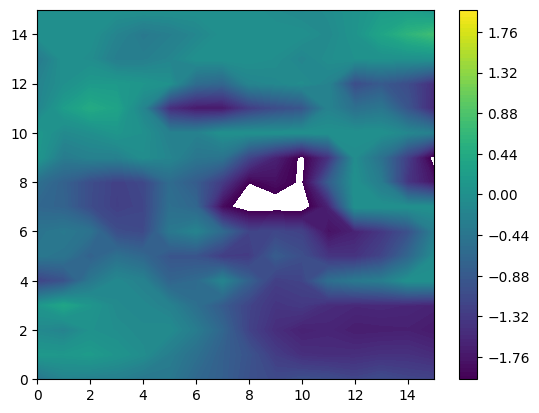

2


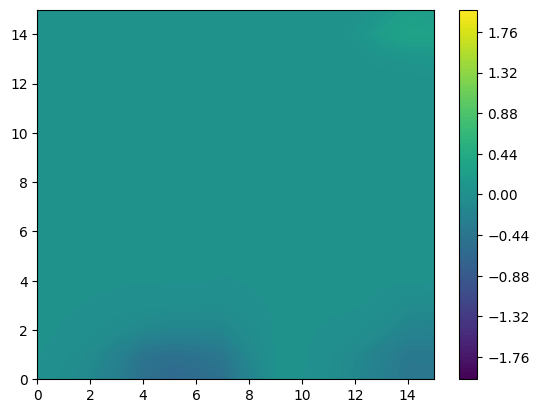

1


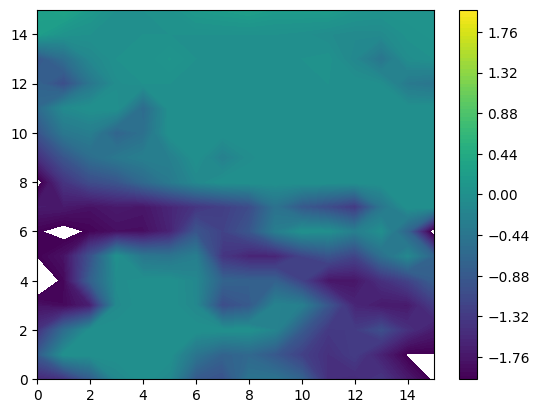

2


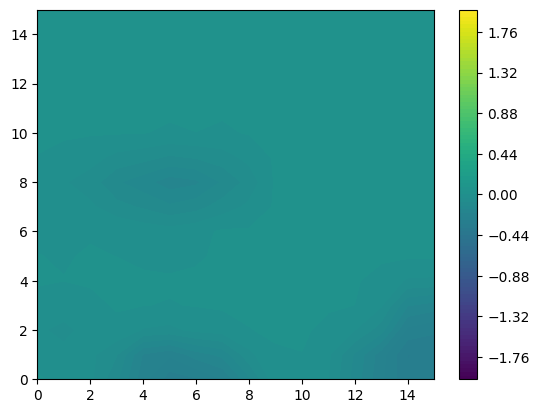

1


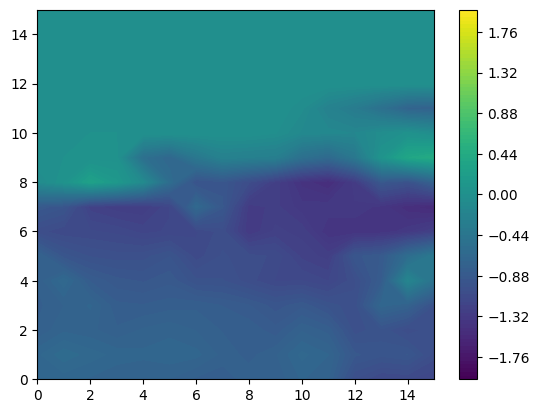

2


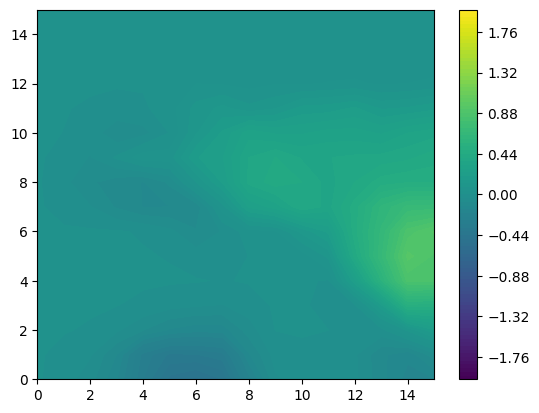

1


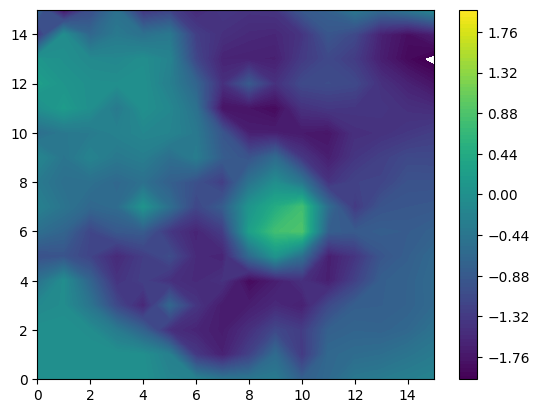

2


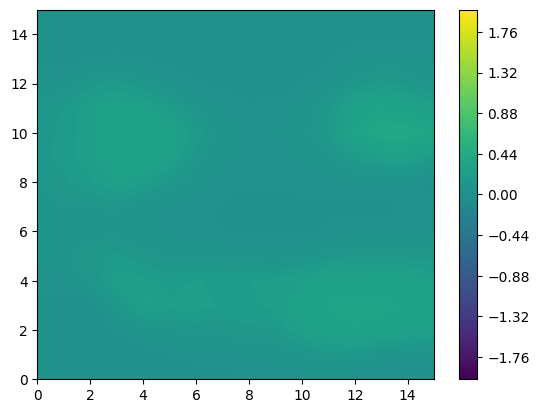

1


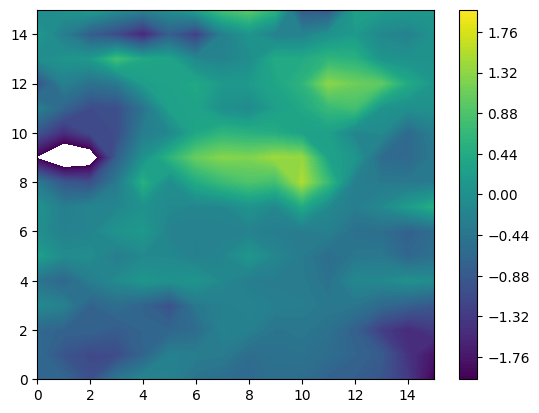

2


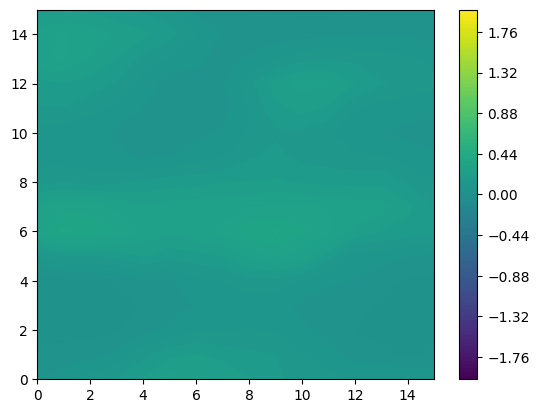

1


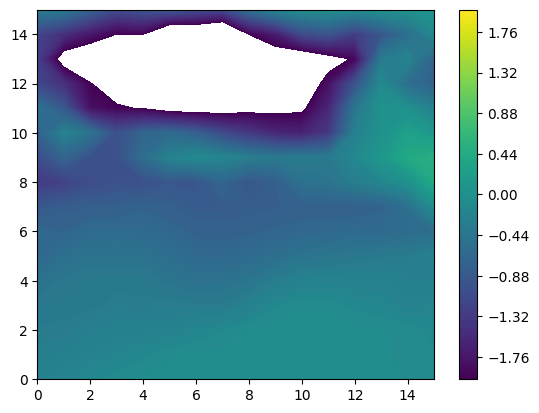

2


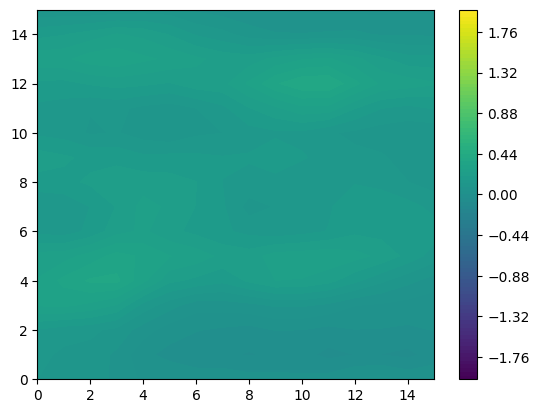

1


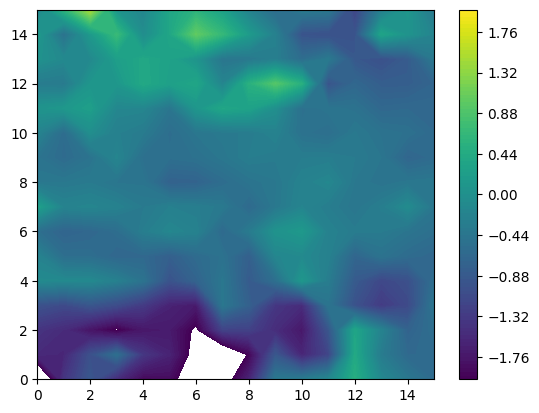

2


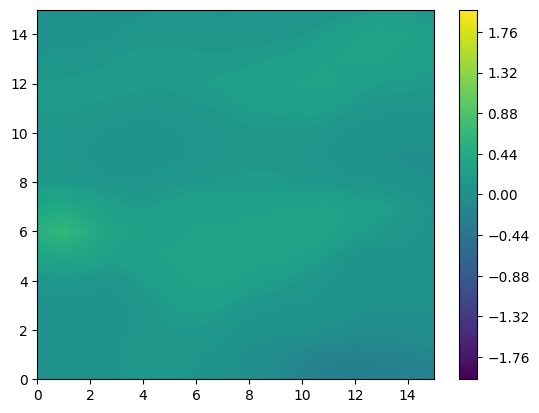

1


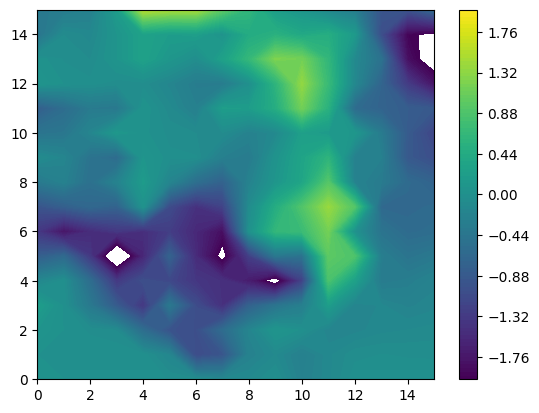

2


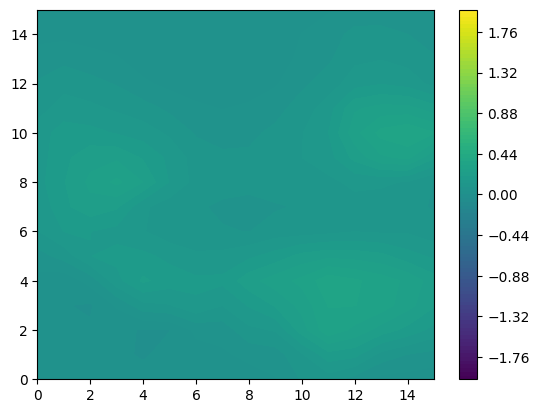

1


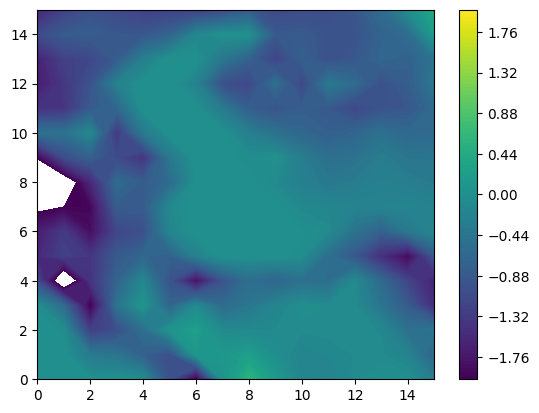

2


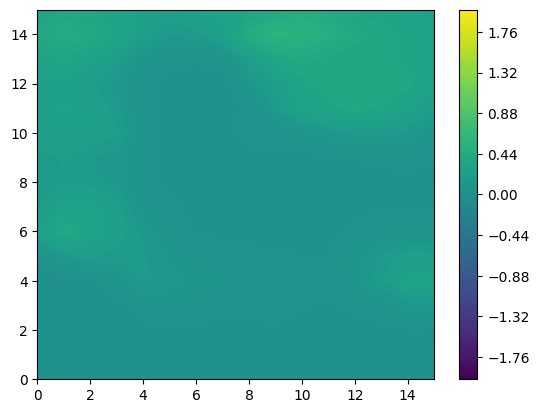

1


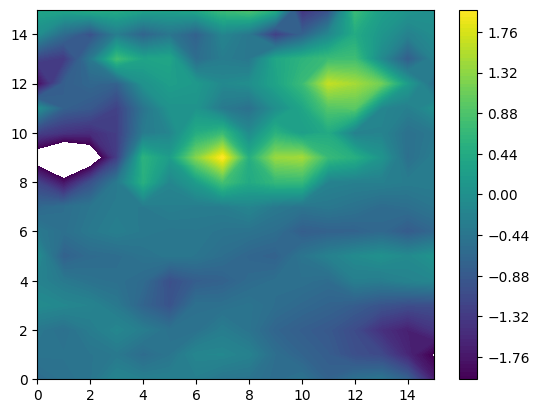

2


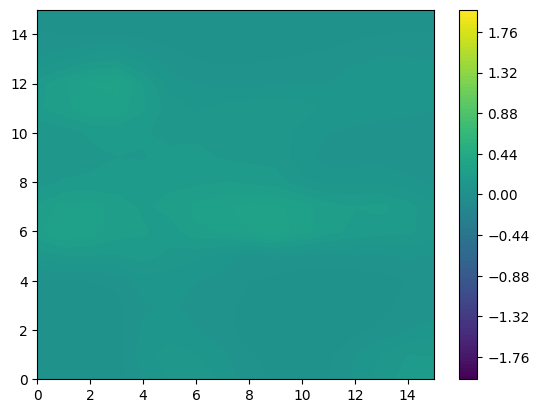

1


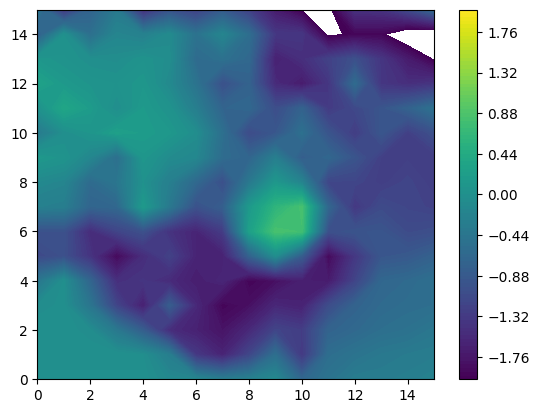

2


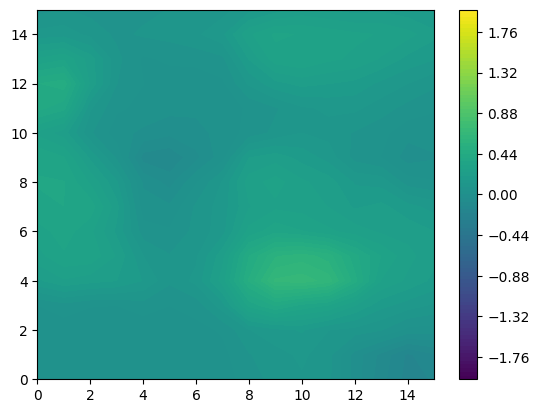

In [37]:
i = 0
with torch.no_grad():
    for X, y in tqdm(ds.loader):
        sda = np.abs(y['sd'][0, 0, :, :].cpu().numpy())
        if np.mean(sda) < 0.5:
            continue
        pred = model(X)[:, 2].cpu().numpy().astype(np.float32)
        i += 1
        print(1)
        plt.contourf(y['sd'][0, 0, :, :], np.linspace(-2, 2, 101))
        plt.colorbar()
        plt.show()
        print(2)
        plt.contourf(pred[0, 0, :, :], np.linspace(-2, 2, 101))
        plt.colorbar()
        plt.show()
        if i > 10:
            break

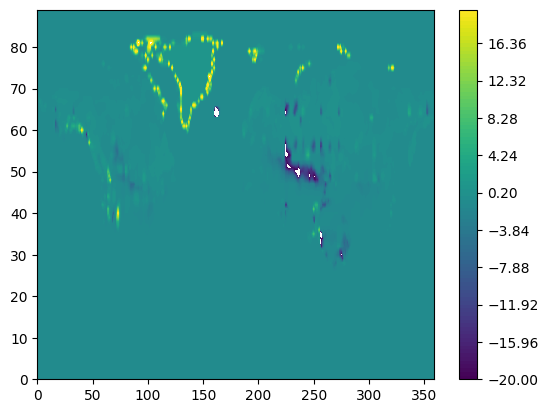

In [21]:
ds = xr.open_dataset(directory / '202412.nc', engine='h5netcdf')
plt.contourf(ds.swe_anom_daily[99, :, :], np.linspace(-20, 20, 100))
plt.colorbar()
plt.show()